# Multiple Linear Regression using Stochastic Gradient Descent

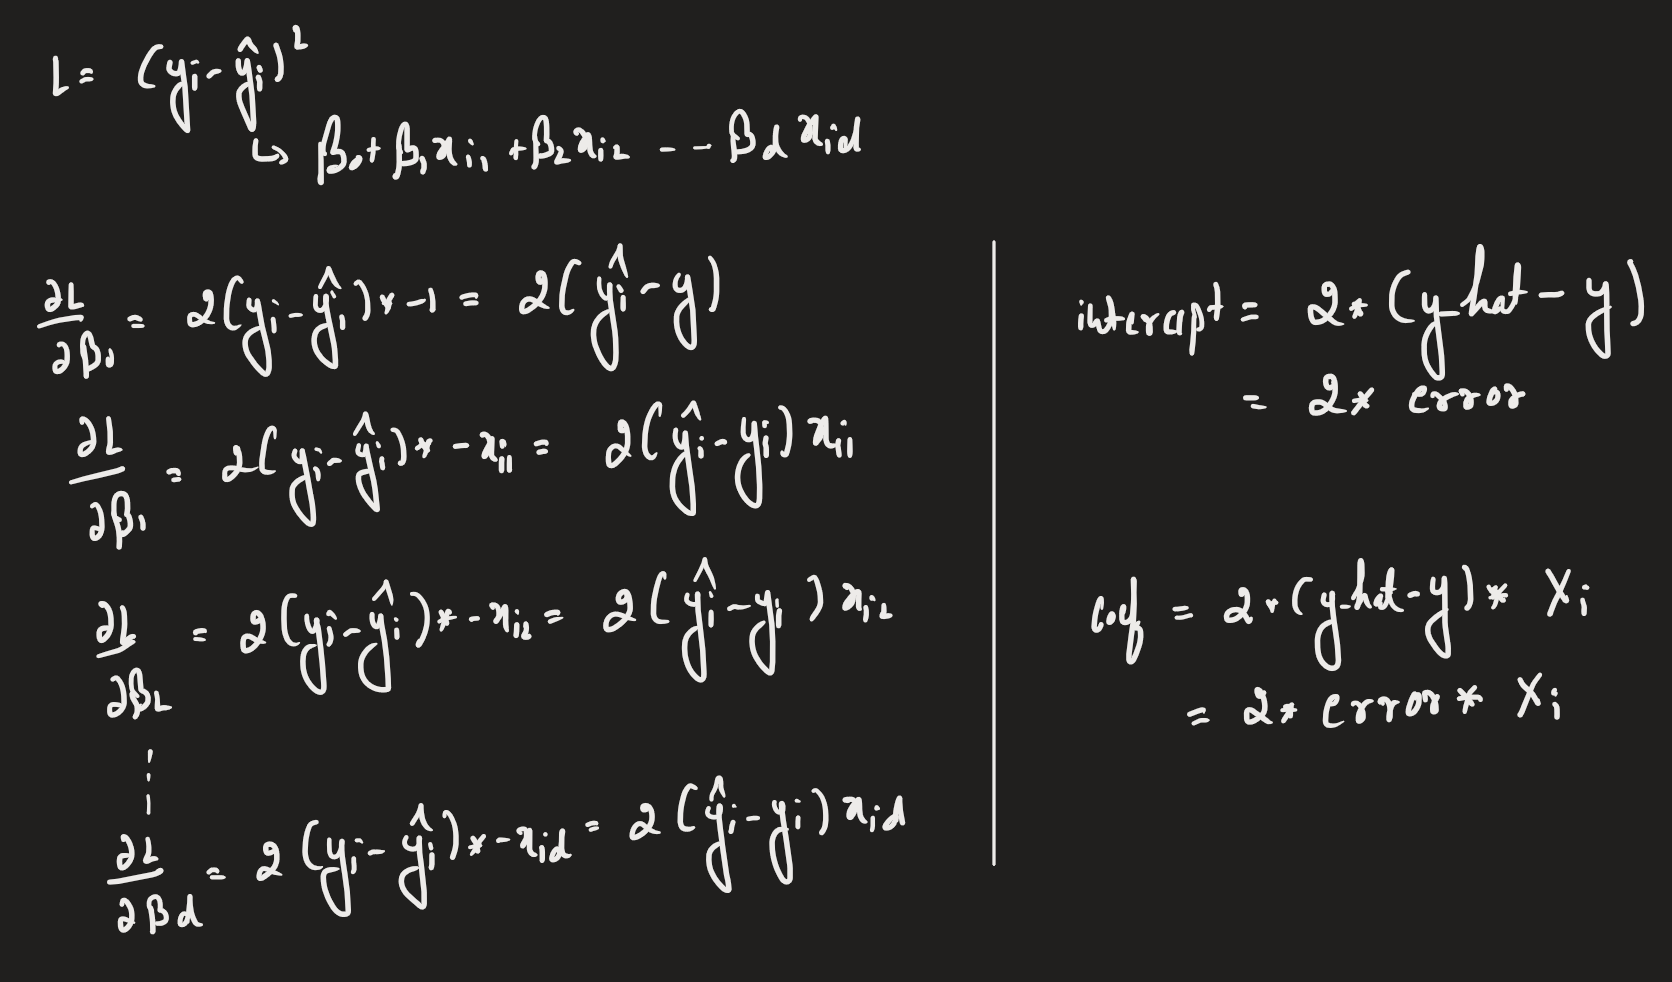

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

In [72]:
class MultipleLinearRegressionSGD:

    def __init__(self, learning_rate: float=0.001, epochs: int=1000, random_state: int=42):

        if learning_rate <= 0:
            raise ValueError("learning_rate must be positive.")

        if epochs < 1:
            raise ValueError("epochs must be at least 1.")
        
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

        self.coef_ = None
        self.intercept_ = None

        self.loss_history_= []
        self.is_fitted_ = False
    
    def fit(self, X: np.ndarray, y: np.ndarray):

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if y.ndim != 1:
            raise ValueError("y must be a 1D array.")

        if X.shape[0] != y.shape[0]:
            raise ValueError("X and y must have the same number of samples.")

        n_samples, n_features = X.shape
        
        # Initialize coefficients and intercept randomly
        rng = np.random.default_rng(self.random_state)
        self.coef_ = rng.normal(loc=0, scale=1, size=n_features)
        self.intercept_ = float(rng.normal(loc=0, scale=1))
        
        for _ in range(self.epochs):
            
            # Shuffle observations at the beginning of each epoch
            shuffled_indexed = rng.permutation(n_samples)

            for idx in shuffled_indexed:

                x_i = X[idx]
                y_i = y[idx]

                y_hat_i = x_i @ self.coef_ + self.intercept_

                error = y_hat_i - y_i

                grad_coef = 2 * error * x_i
                grad_intercept = 2 * error 
            
                self.coef_ = self.coef_ - self.learning_rate * grad_coef
                self.intercept_ = self.intercept_ - self.learning_rate * grad_intercept
            
            # Calculate full training MSE after each epoch
            y_train_pred = X @ self.coef_ + self.intercept_
            epoch_loss = np.mean( (y - y_train_pred)**2)
            self.loss_history_.append(epoch_loss)

        self.is_fitted_ = True
    
    def predict(self, X: np.ndarray):

        if not self.is_fitted_:
            raise ValueError("Fit the model before making predictions.")
        
        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        
        if X.shape[1] != self.coef_.shape[0]:
            raise ValueError("X must have the same number of features used during training.")
        
        return X @ self.coef_ + self.intercept_

In [73]:
# Load the Diabetes dataset

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,)

In [75]:
# Standardize the input features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [76]:
# Train the model

mlr_sgd = MultipleLinearRegressionSGD(
    learning_rate=0.001,
    epochs=100,
    random_state=42
)

mlr_sgd.fit(X_train_scaled, y_train)

In [77]:
mlr_sgd.coef_

array([  2.27339998, -11.07184089,  25.87711023,  17.21444868,
       -22.29205765,   8.67839391,  -1.00113078,   9.95693906,
        26.9197584 ,   2.46908582])

In [78]:
mlr_sgd.intercept_

np.float64(154.39029509817001)

In [79]:
# Make predictions on the test data

y_pred = mlr_sgd.predict(X_test_scaled)

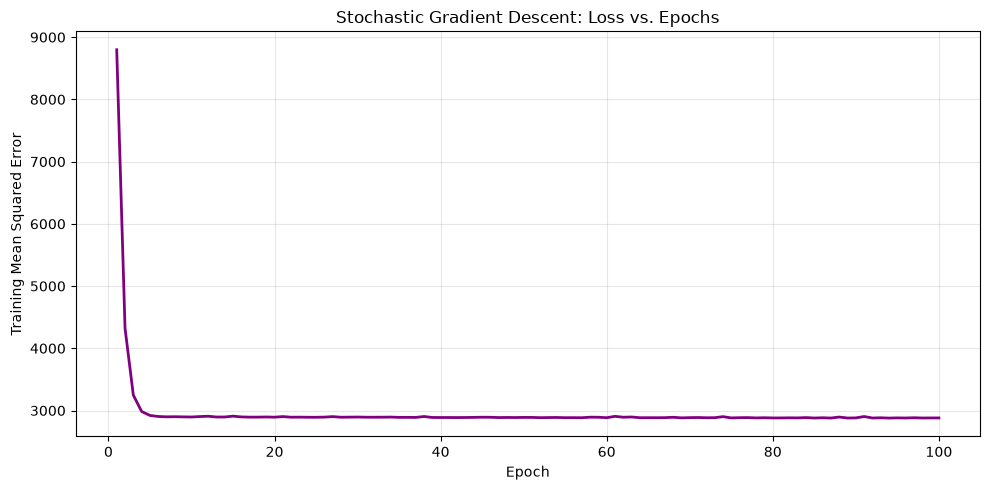

In [80]:
# Visualize loss during training

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, mlr_sgd.epochs + 1),
    mlr_sgd.loss_history_,
    color="purple",
    linewidth=2,
)

plt.title("Stochastic Gradient Descent: Loss vs. Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Mean Squared Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
# Evaluate the model

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  42.9187
MSE:  2869.9491
RMSE: 53.5719
R²:   0.4583
